# NOTEBOOK 1 : PRÉPARATION DES DONNÉES ET EDA

## Dataset: DeepGlobe Land Cover Classification

## Cellule 1 :  Imports et Configuration



Cette cellule importe toutes les bibliothèques nécessaires pour le notebook et configure l'environnement de travail.

---

### Détail des imports :

| Bibliothèque | Rôle |
|--------------|------|
| `os`, `Path` | Gestion des chemins de fichiers et dossiers |
| `json` | Sauvegarde/lecture des métadonnées au format JSON |
| `random`, `numpy` | Génération de nombres aléatoires (pour reproductibilité) |
| `pandas` | Manipulation de données tabulaires (statistiques) |
| `Counter` | Comptage des occurrences (distribution des classes) |
| `typing` | Annotations de types pour un code plus lisible |
| `warnings.filterwarnings('ignore')` | Supprimer les avertissements pour un affichage propre |

**Traitement d'images :**
| Bibliothèque | Rôle |
|--------------|------|
| `cv2` (OpenCV) | Lecture, redimensionnement, manipulation des images |
| `PIL` | Traitement d'images alternatif |
| `distance_transform_edt` | Calcul de distances euclidiennes (pour remplacer la classe "unknown") |

**Visualisation :**
| Bibliothèque | Rôle |
|--------------|------|
| `matplotlib` | Graphiques et affichage d'images |
| `seaborn` | Graphiques statistiques élégants |
| `plotly` | Graphiques interactifs |

**Utilitaires :**
| Bibliothèque | Rôle |
|--------------|------|
| `tqdm` | Barres de progression pour les boucles longues |
| `datetime` | Horodatage de l'exécution |

---

### Pourquoi :

1. **Organisation** : Regrouper tous les imports au début permet de voir rapidement les dépendances du projet

2. **Traitement d'images satellites** : OpenCV et PIL sont essentiels pour lire les images `.jpg` et les masques `.png`, les redimensionner et les convertir

3. **Analyse exploratoire (EDA)** : Matplotlib, Seaborn et Plotly permettent de visualiser les données pour mieux les comprendre avant l'entraînement

4. **Reproductibilité** :  Le message d'exécution avec la date et le répertoire de travail permet de tracer quand et où le notebook a été exécuté

5. **Style uniforme** : `plt.style.use('seaborn-v0_8-darkgrid')` et `sns.set_palette("husl")` assurent des graphiques cohérents et esthétiques dans tout le notebook

In [ ]:
# ========================================================================================================
# 1. IMPORTS ET CONFIGURATION
# ========================================================================================================
import os
import json
import random
import numpy as np
import pandas as pd
from pathlib import Path
from typing import Dict, List, Tuple, Optional
from collections import Counter
import warnings
warnings.filterwarnings('ignore')

# Image processing
import cv2
from PIL import Image
from scipy.ndimage import distance_transform_edt

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
import plotly.express as px
import plotly.graph_objects as go

# Utils
from tqdm.auto import tqdm
from datetime import datetime

# Set style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

print("="*80)
print("DEEPGLOBE LAND COVER SEGMENTATION - DATA PREPARATION & EDA ")
print("="*80)
print(f"\nExecution Date: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Working Directory: {os.getcwd()}")

DEEPGLOBE LAND COVER SEGMENTATION - DATA PREPARATION & EDA 

Execution Date: 2025-12-18 10:22:51
Working Directory: /kaggle/working


## Cellule 2 :  Configuration Globale


Cette cellule définit une classe `Config` qui centralise **tous les paramètres du projet** en un seul endroit, puis crée les dossiers de sortie nécessaires.

---

### Détail des paramètres :

| Paramètre | Valeur | Rôle |
|-----------|--------|------|
| `SEED` | 42 | Graine aléatoire pour garantir la reproductibilité |
| `DATA_DIR` | `/kaggle/input/... ` | Chemin vers le dataset DeepGlobe |
| `TRAIN_DIR`, `TEST_DIR` | sous-dossiers | Chemins vers les images d'entraînement et de test |
| `OUTPUT_DIR` | `/kaggle/working/preprocessed_data` | Où sauvegarder les données prétraitées |
| `MODELS_DIR` | `/kaggle/working/models` | Où sauvegarder les modèles (pour notebooks suivants) |
| `FIGURES_DIR` | `/kaggle/working/figures` | Où sauvegarder les graphiques |
| `TARGET_SIZE` | (256, 256) | Taille de redimensionnement des images |
| `VAL_SPLIT` | 0.2 | 20% des données pour la validation |
| `CLASS_NAMES` | liste de 7 classes | Noms des catégories de couverture terrestre |
| `CLASS_COLORS` | dictionnaire RGB | Correspondance couleur → classe dans les masques |
| `MEAN`, `STD` | stats ImageNet | Valeurs de normalisation standard pour réseaux pré-entraînés |
| `REMOVE_UNKNOWN_CLASS` | True | Supprimer la classe "unknown" ambiguë |
| `COMPUTE_DATASET_STATS` | True | Calculer les vraies statistiques RGB du dataset |

---

### Pourquoi :

1. **Centralisation** : Modifier un paramètre (ex: `TARGET_SIZE`) à un seul endroit affecte tout le notebook — évite les erreurs et incohérences

2. **Reproductibilité** :  Le `SEED=42` garantit que les mêmes résultats seront obtenus à chaque exécution (splits, augmentations aléatoires)

3. **Correspondance couleur-classe** : Les masques DeepGlobe sont en RGB (ex: cyan = urban). `CLASS_COLORS` permet de convertir ces couleurs en indices numériques (0, 1, 2.. .) que U-Net peut traiter

4. **Taille cible 256×256** :  Les images originales (2448×2448) sont trop grandes pour la mémoire GPU.  256×256 est un bon compromis entre détail et efficacité

5. **Statistiques ImageNet** : Les valeurs `MEAN` et `STD` sont les standards pour les réseaux pré-entraînés sur ImageNet (utile si on utilise un encodeur pré-entraîné comme VGG)

6. **Création des dossiers** : `mkdir(parents=True, exist_ok=True)` crée les dossiers s'ils n'existent pas, sans erreur s'ils existent déjà — prépare la structure pour sauvegarder les résultats

In [ ]:
# ========================================================================================================
# 2. CONFIGURATION GLOBALE
# ========================================================================================================
class Config:
    """Configuration centralisée du projet"""

    # Reproductibilité
    SEED = 42

    # Chemins
    DATA_DIR = Path('/kaggle/input/deepglobe-land-cover-classification-dataset')
    TRAIN_DIR = DATA_DIR / 'train'
    TEST_DIR = DATA_DIR / 'test'

    # Chemins de sortie
    OUTPUT_DIR = Path('/kaggle/working/preprocessed_data')
    MODELS_DIR = Path('/kaggle/working/models')
    FIGURES_DIR = Path('/kaggle/working/figures')

    # Paramètres de prétraitement
    TARGET_SIZE = (256, 256)
    VAL_SPLIT = 0.2

    # Classes de segmentation
    CLASS_NAMES = [
        'urban',        # 0 - Urban land
        'agriculture',  # 1 - Agriculture land
        'rangeland',    # 2 - Rangeland
        'forest',       # 3 - Forest land
        'water',        # 4 - Water
        'barren',       # 5 - Barren land
        'unknown'       # 6 - Unknown (to be removed)
    ]

    # Couleurs RGB pour chaque classe
    CLASS_COLORS = {
        0: (0, 255, 255),      # urban - cyan
        1: (255, 255, 0),      # agriculture - yellow
        2: (255, 0, 255),      # rangeland - magenta
        3: (0, 255, 0),        # forest - green
        4: (0, 0, 255),        # water - blue
        5: (255, 255, 255),    # barren - white
        6: (0, 0, 0)           # unknown - black
    }

    # Normalisation (ImageNet statistics)
    MEAN = [0.485, 0.456, 0.406]
    STD = [0.229, 0.224, 0.225]

    # Paramètres d'analyse
    REMOVE_UNKNOWN_CLASS = True  # Remplacer classe "unknown" par classe la plus proche
    COMPUTE_DATASET_STATS = True  # Calculer vraies stats du dataset

config = Config()

# Création des dossiers
for directory in [config.OUTPUT_DIR, config.MODELS_DIR, config.FIGURES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
    print(f"✓ Created directory: {directory}")

✓ Created directory: /kaggle/working/preprocessed_data
✓ Created directory: /kaggle/working/models
✓ Created directory: /kaggle/working/figures


## Cellule 3 :   Reproductibilité


Cette cellule définit une fonction `set_seed()` qui fixe les générateurs de nombres aléatoires à une valeur déterminée (42), puis l'exécute.

---

### Détail des seeds fixés :

| Commande | Ce qu'elle contrôle |
|----------|---------------------|
| `random.seed(seed)` | Module `random` de Python (ex: `random.choice()`, `random.shuffle()`) |
| `np.random.seed(seed)` | NumPy (ex:  `np.random.randint()`, `np.random.choice()`) |
| `os.environ['PYTHONHASHSEED']` | Hashage interne de Python (ordre des dictionnaires, sets) |

---

### Pourquoi :

1. **Reproductibilité scientifique** : En fixant le seed, on garantit que :
   - Le split train/validation sera **identique** à chaque exécution
   - Les échantillons aléatoires affichés seront **les mêmes**
   - Les résultats peuvent être **vérifiés et reproduits** par d'autres chercheurs

2. **Débogage facilité** : Si un problème survient, on peut le reproduire exactement dans les mêmes conditions

3. **Comparaison équitable** : Quand on comparera U-Net, VGG et DeepLabV3+ dans les notebooks suivants, ils utiliseront **exactement les mêmes données** de train/validation

4. **Valeur 42** : C'est une convention dans la communauté ML (référence au "Guide du voyageur galactique"). N'importe quelle valeur fonctionnerait, mais 42 est un standard reconnu.

In [ ]:
# ========================================================================================================
# 3. REPRODUCTIBILITÉ
# ========================================================================================================
def set_seed(seed: int = 42):
    """Fixe tous les seeds pour reproductibilité"""
    random.seed(seed)
    np.random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    print(f"\n✓ All seeds set to {seed} for reproducibility")

set_seed(config.SEED)


✓ All seeds set to 42 for reproducibility


## Cellule 4 :   Fonctions Utilitaires


Cette cellule définit **6 fonctions réutilisables** qui seront appelées tout au long du notebook pour manipuler les fichiers, convertir les masques et analyser les données.

---

### Détail de chaque fonction :  

#### 1. `get_file_paths(directory, extension)`
```python
# Exemple:  get_file_paths(TRAIN_DIR, '*_sat.jpg')
# Retourne:  [Path('001_sat.jpg'), Path('002_sat.jpg'), ...]
```
**Rôle** :  Récupère tous les fichiers correspondant à un pattern dans un dossier  
**Pourquoi** :  Permet de lister automatiquement toutes les images et masques du dataset

---

#### 2. `rgb_to_class_mask(rgb_mask, class_colors)`
```python
# Entrée:  Image RGB où cyan=(0,255,255) représente "urban"
# Sortie: Masque 2D où les pixels cyan deviennent 0 (indice de urban)
```
**Rôle** : Convertit un masque coloré RGB en masque d'indices de classes (0-6)  
**Pourquoi** : U-Net attend des masques avec des **valeurs entières** (0, 1, 2.. .), pas des couleurs RGB.  Cette conversion est **essentielle** pour l'entraînement

---

#### 3. `class_mask_to_rgb(class_mask, class_colors)`
```python
# Entrée: Masque 2D avec valeurs 0-6
# Sortie:  Image RGB colorée pour visualisation
```
**Rôle** : Conversion inverse — transforme les indices en couleurs  
**Pourquoi** : Pour **visualiser** les prédictions du modèle de manière compréhensible par l'humain

---

#### 4. `replace_unknown_class(mask, unknown_class=6)`
```python
# Entrée: Masque avec des pixels "unknown" (classe 6)
# Sortie:  Masque où chaque pixel unknown est remplacé par sa classe voisine la plus proche
```
**Rôle** : Élimine la classe "unknown" en utilisant la **distance euclidienne**  
**Pourquoi** :
- La classe "unknown" (0. 05% des pixels) représente des zones ambiguës sans valeur sémantique
- Plutôt que de l'ignorer, on la remplace intelligemment par la classe du pixel **connu le plus proche spatialement**
- Cela évite d'avoir une 7ème classe inutile qui perturberait l'apprentissage

---

#### 5. `calculate_class_distribution(mask, num_classes)`
```python
# Entrée: Un masque de segmentation
# Sortie: {'0': 15.2%, '1': 45.3%, '2': 8.1%, ... }
```
**Rôle** : Calcule le pourcentage de pixels de chaque classe  
**Pourquoi** : Permet de détecter le **déséquilibre des classes** (ex: agriculture = 57%, water = 3%)

---

#### 6. `analyze_image_complexity(mask)`
```python
# Sortie: {'num_classes': 4, 'total_segments': 25, 'fragmentation': 6.25}
```
**Rôle** : Mesure la complexité d'une scène via :
- **num_classes** :  Combien de classes différentes sont présentes
- **total_segments** :  Nombre de régions disjointes (composantes connexes)
- **fragmentation** :  Ratio segments/classes (plus c'est élevé, plus l'image est fragmentée)

**Pourquoi** : Comprendre la difficulté des images — une image très fragmentée avec beaucoup de petites zones sera plus difficile à segmenter qu'une image homogène

In [ ]:
# ========================================================================================================
# 4. FONCTIONS UTILITAIRES
# ========================================================================================================
def get_file_paths(directory: Path, extension: str = '*') -> List[Path]:
    """Récupère tous les chemins de fichiers avec une extension donnée"""
    return sorted(list(directory.glob(f'**/{extension}')))

def rgb_to_class_mask(rgb_mask: np.ndarray, class_colors: Dict) -> np.ndarray:
    """Convertit un masque RGB en masque de classes"""
    h, w = rgb_mask.shape[:2]
    class_mask = np.zeros((h, w), dtype=np.uint8)

    for class_id, color in class_colors.items():
        mask = np.all(rgb_mask == color, axis=-1)
        class_mask[mask] = class_id

    return class_mask

def class_mask_to_rgb(class_mask: np.ndarray, class_colors: Dict) -> np.ndarray:
    """Convertit un masque de classes en masque RGB"""
    h, w = class_mask.shape
    rgb_mask = np.zeros((h, w, 3), dtype=np.uint8)

    for class_id, color in class_colors.items():
        rgb_mask[class_mask == class_id] = color

    return rgb_mask

def replace_unknown_class(mask: np.ndarray, unknown_class: int = 6) -> np.ndarray:
    """
    Remplace les pixels 'unknown' par la classe la plus proche spatialement.
    Utilise la distance euclidienne transform pour trouver le pixel connu le plus proche.
    """
    new_mask = mask.copy()
    known_mask = (mask != unknown_class)

    if known_mask.sum() == 0:
        return new_mask

    # Distance transform: trouve le pixel connu le plus proche
    distances, indices = distance_transform_edt(known_mask == 0, return_indices=True)

    # Remplacer les pixels unknown par la classe du pixel connu le plus proche
    new_mask[~known_mask] = mask[indices[0][~known_mask], indices[1][~known_mask]]

    return new_mask

def calculate_class_distribution(mask: np.ndarray, num_classes: int = 7) -> Dict[int, float]:
    """Calcule la distribution des classes dans un masque"""
    total_pixels = mask.size
    class_dist = {}

    for class_id in range(num_classes):
        count = np.sum(mask == class_id)
        class_dist[class_id] = (count / total_pixels) * 100

    return class_dist

def analyze_image_complexity(mask: np.ndarray) -> Dict:
    """Analyse la complexité d'une scène (nombre de classes, fragmentation)"""
    unique_classes = np.unique(mask)
    num_classes = len(unique_classes)

    # Calculer le nombre de segments (composantes connexes) par classe
    from scipy import ndimage
    total_segments = 0

    for class_id in unique_classes:
        binary_mask = (mask == class_id).astype(np.uint8)
        labeled, num_features = ndimage.label(binary_mask)
        total_segments += num_features

    return {
        'num_classes': num_classes,
        'total_segments': total_segments,
        'fragmentation': total_segments / num_classes if num_classes > 0 else 0
    }

## Cellule 5 :    Exploration Initiale du Dataset

Cette cellule effectue une **première reconnaissance du dataset** en comptant les fichiers et en vérifiant leur intégrité.  

---

### Détail des opérations :  

| Opération | Résultat |
|-----------|----------|
| Lister les images satellites (`*_sat.jpg`) | 803 images d'entraînement |
| Lister les masques (`*_mask.png`) | 803 masques |
| Lister les images de test | 172 images |
| Vérifier la correspondance | ✓ Parfaite (803 = 803) |

---

### Structure des fichiers DeepGlobe :  

```
train/
  ├── 12345_sat.jpg    ← Image satellite
  ├── 12345_mask.png   ← Masque de segmentation correspondant
  ├── 67890_sat.jpg
  ├── 67890_mask. png
  └── ...

test/
  ├── 11111_sat.jpg    ← Pas de masque (pour évaluation finale)
  └── ...
```

---

### Pourquoi :   

1. **Validation des données** :   Avant tout traitement, on doit s'assurer que :  
   - Le dataset est **complet** (pas de fichiers manquants)
   - Chaque image a **son masque correspondant** (même ID)
   - Les fichiers sont **accessibles** et bien nommés

2. **Détection d'erreurs précoce** :  Si un masque manquait, le notebook planterait plus tard lors du preprocessing.   Mieux vaut le détecter **maintenant** avec un message clair

3. **Compréhension du volume** :
   - **803 images d'entraînement** → seront divisées en train/validation
   - **172 images de test** → sans masques, pour l'évaluation finale
   - C'est un dataset de taille moyenne, adapté à l'apprentissage profond

4. **Convention de nommage** : La vérification `12345_sat. jpg` ↔ `12345_mask.png` confirme que le dataset suit une convention cohérente, ce qui simplifie le chargement des paires image-masque

In [ ]:
# ========================================================================================================
# 5. EXPLORATION INITIALE
# ========================================================================================================
print("\n" + "="*80)
print("5. EXPLORATION INITIALE DU DATASET")
print("="*80)

train_images = get_file_paths(config.TRAIN_DIR, '*_sat.jpg')
train_masks = get_file_paths(config.TRAIN_DIR, '*_mask.png')
test_images = get_file_paths(config.TEST_DIR, '*_sat.jpg')

print(f"\n Statistiques initiales:")
print(f"  • Images d'entraînement: {len(train_images)}")
print(f"  • Masques d'entraînement: {len(train_masks)}")
print(f"  • Images de test: {len(test_images)}")
print(f"  • Correspondance image-masque: {len(train_images) == len(train_masks)}")

# Vérifier la correspondance exacte des noms
print("\n Vérification de la correspondance image-masque:")
mismatches = []
for img_path in train_images[:10]:  # Vérifier les 10 premiers
    img_id = img_path.stem.replace('_sat', '')
    expected_mask = img_path.parent / f"{img_id}_mask.png"
    if not expected_mask.exists():
        mismatches.append(img_id)

if mismatches:
    print(f"  {len(mismatches)} désappariements trouvés")
else:
    print(f"  ✓ Tous les fichiers sont correctement appariés")


5. EXPLORATION INITIALE DU DATASET

 Statistiques initiales:
  • Images d'entraînement: 803
  • Masques d'entraînement: 803
  • Images de test: 172
  • Correspondance image-masque: True

 Vérification de la correspondance image-masque:
  ✓ Tous les fichiers sont correctement appariés


## Cellule 6 :     Analyse Approfondie des Images


Cette cellule analyse les **propriétés de toutes les 803 images** d'entraînement :  dimensions, statistiques de couleur par canal RGB.  

---

### Détail des mesures collectées :  

| Mesure | Description | Résultat |
|--------|-------------|----------|
| `height`, `width` | Dimensions en pixels | Toutes 2448×2448 (uniformes) |
| `channels` | Nombre de canaux | 3 (RGB) |
| `mean_R/G/B` | Moyenne de chaque canal | R≈104, G≈97, B≈72 |
| `std_R/G/B` | Écart-type de chaque canal | R≈32, G≈26, B≈23 |
| `min_val`, `max_val` | Valeurs extrêmes | 0-255 |

---

### Statistiques normalisées [0, 1] calculées :  

```
Mean:  [0.4082, 0.3791, 0.2816]
Std:   [0.1272, 0.1010, 0.0890]
```

---

### Pourquoi :    

1. **Vérifier l'uniformité des dimensions** :
   - Toutes les images font **2448×2448** → pas besoin de gérer des tailles variables
   - Simplifie le preprocessing (un seul redimensionnement vers 256×256)

2. **Comprendre la distribution des couleurs** :  
   - **Rouge > Vert > Bleu** : typique des images satellites terrestres (végétation, sols)
   - Les valeurs moyennes (~100/255) indiquent des images plutôt sombres
   - La variabilité (std) montre une bonne diversité dans le dataset

3. **Calculer les statistiques propres au dataset** :  
   - **ImageNet stats** : Mean=[0.485, 0.456, 0.406] — pour réseaux pré-entraînés
   - **DeepGlobe stats** :  Mean=[0.408, 0.379, 0.282] — spécifiques à ce dataset
   - Ces statistiques serviront à la **normalisation** pendant l'entraînement
   - Utiliser les vraies stats du dataset peut améliorer les performances par rapport aux stats ImageNet génériques

4. **Détecter des anomalies** :  
   - Si une image avait des dimensions différentes ou des valeurs aberrantes, on le verrait ici
   - `min=0`, `max=255` confirme que les images utilisent toute la plage de valeurs

In [ ]:
# ========================================================================================================
# 6. ANALYSE APPROFONDIE DES IMAGES
# ========================================================================================================
print("\n" + "="*80)
print("6. ANALYSE APPROFONDIE DES IMAGES")
print("="*80)

def analyze_image_properties(image_paths: List[Path], sample_size: int = None) -> pd.DataFrame:
    """Analyse les propriétés des images"""
    if sample_size:
        image_paths = random.sample(image_paths, min(sample_size, len(image_paths)))

    stats = []
    for img_path in tqdm(image_paths, desc="Analyzing images"):
        img = cv2.imread(str(img_path))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w, c = img.shape

        stats.append({
            'filename': img_path.name,
            'height': h,
            'width': w,
            'channels': c,
            'mean_R': img[:,:,0].mean(),
            'mean_G': img[:,:,1].mean(),
            'mean_B': img[:,:,2].mean(),
            'std_R': img[:,:,0].std(),
            'std_G': img[:,:,1].std(),
            'std_B': img[:,:,2].std(),
            'min_val': img.min(),
            'max_val': img.max()
        })

    return pd.DataFrame(stats)

# Analyser toutes les images
print("\n Analyse de toutes les images d'entraînement...")
train_stats = analyze_image_properties(train_images)

print("\n Statistiques des dimensions:")
print(train_stats[['height', 'width']].describe())

print("\n Statistiques RGB globales:")
print(train_stats[['mean_R', 'mean_G', 'mean_B', 'std_R', 'std_G', 'std_B']].describe())

# Calculer les vraies statistiques du dataset (normalisées [0,1])
if config.COMPUTE_DATASET_STATS:
    dataset_mean_R = train_stats['mean_R'].mean() / 255.0
    dataset_mean_G = train_stats['mean_G'].mean() / 255.0
    dataset_mean_B = train_stats['mean_B'].mean() / 255.0

    dataset_std_R = train_stats['std_R'].mean() / 255.0
    dataset_std_G = train_stats['std_G'].mean() / 255.0
    dataset_std_B = train_stats['std_B'].mean() / 255.0

    print(f"\n Statistiques réelles du dataset (normalisé [0,1]):")
    print(f"  Mean: [{dataset_mean_R:.4f}, {dataset_mean_G:.4f}, {dataset_mean_B:.4f}]")
    print(f"  Std:  [{dataset_std_R:.4f}, {dataset_std_G:.4f}, {dataset_std_B:.4f}]")


6. ANALYSE APPROFONDIE DES IMAGES

 Analyse de toutes les images d'entraînement...


Analyzing images:   0%|          | 0/803 [00:00<?, ?it/s]


 Statistiques des dimensions:
       height   width
count   803.0   803.0
mean   2448.0  2448.0
std       0.0     0.0
min    2448.0  2448.0
25%    2448.0  2448.0
50%    2448.0  2448.0
75%    2448.0  2448.0
max    2448.0  2448.0

 Statistiques RGB globales:
           mean_R      mean_G      mean_B       std_R       std_G       std_B
count  803.000000  803.000000  803.000000  803.000000  803.000000  803.000000
mean   104.094886   96.668538   71.805762   32.427772   25.751623   22.696864
std     17.150525   11.911146   12.167246    7.791085    7.114867    7.240477
min     41.480803   51.236659   43.180718   14.331891   10.758917   10.704277
25%     94.919431   89.222711   63.662387   26.678536   20.514217   17.444571
50%    104.460005   97.469344   71.060704   32.096550   25.007187   21.345700
75%    115.974363  104.179480   78.402255   37.650968   30.276734   26.587728
max    153.538755  136.603824  125.233119   62.357328   53.426290   55.080532

 Statistiques réelles du dataset (norma

## Interprétation Détaillée des Résultats de la Cellule 6

---

### 1. Statistiques des Dimensions

```
       height   width
count   803.0   803.0
mean   2448.0  2448.0
std       0.0     0.0
min    2448.0  2448.0
max    2448.0  2448.0
```

| Observation | Interprétation |
|-------------|----------------|
| `count = 803` | Toutes les 803 images ont été analysées avec succès |
| `mean = 2448` | Dimension moyenne = 2448 pixels |
| `std = 0.0` | **Aucune variation** — toutes les images ont exactement la même taille |
| `min = max = 2448` | Confirme l'uniformité parfaite |

**Conclusion** : Le dataset est **parfaitement homogène** en termes de dimensions.  Toutes les images font **2448×2448 pixels**. C'est idéal car on n'a pas besoin de gérer des tailles différentes lors du preprocessing.

---

### 2. Statistiques RGB Globales (valeurs 0-255)

#### Moyennes par canal (`mean_R`, `mean_G`, `mean_B`)

```
       mean_R      mean_G      mean_B
mean   104.09      96.67       71.81
```

| Canal | Moyenne | Interprétation |
|-------|---------|----------------|
| **Rouge** | 104.09 | Le plus élevé → sols, terres agricoles |
| **Vert** | 96.67 | Moyen → végétation (forêts, cultures) |
| **Bleu** | 71.81 | Le plus faible → peu d'eau dans les images |

**Interprétation** :  Les images satellites sont dominées par des **tons chauds** (rouge-vert). Cela correspond à des paysages terrestres :  agriculture (jaune/marron), forêts (vert), zones urbaines (gris/rouge). Le bleu faible indique peu de surfaces d'eau.

---

#### Variabilité entre images (`std` des moyennes)

```
       mean_R      mean_G      mean_B
std    17.15       11.91       12.17
```

| Observation | Interprétation |
|-------------|----------------|
| `std ≈ 12-17` | Les images ont des **ambiances colorimétriques variées** |
| Rouge plus variable | Diversité des types de sols et constructions |

**Interprétation** :  Le dataset contient des images **diversifiées** — certaines plus vertes (forêts), d'autres plus rouges (déserts, villes). C'est positif pour l'entraînement :  le modèle verra des conditions variées.

---

#### Écart-type intra-image (`std_R`, `std_G`, `std_B`)

```
       std_R       std_G       std_B
mean   32.43       25.75       22.70
```

| Observation | Interprétation |
|-------------|----------------|
| `std ≈ 23-32` | Chaque image a une **bonne variabilité interne** |
| Pas trop faible | Les images ne sont pas uniformes (bonnes textures) |
| Pas trop élevé | Les images ne sont pas trop bruitées |

**Interprétation** : Les images contiennent des **textures riches et variées** — mélanges de classes (forêt + eau + urbain dans la même image). C'est bon signe pour l'apprentissage de la segmentation.

---

#### Valeurs extrêmes

```
       mean_R      mean_G      mean_B
min    41.48       51.24       43.18      → Image la plus sombre
max    153.54      136.60      125.23     → Image la plus claire
```

**Interprétation** :
- **Image la plus sombre** (min≈45) :  probablement une zone très forestière ou une image prise dans des conditions de faible luminosité
- **Image la plus claire** (max≈140) :  probablement une zone désertique, enneigée ou très urbanisée
- L'écart min-max montre une **grande diversité** de conditions d'éclairage et de types de terrains

---

### 3. Statistiques Normalisées [0, 1]

```
Mean: [0.4082, 0.3791, 0.2816]
Std:  [0.1272, 0.1010, 0.0890]
```

#### Comparaison avec ImageNet

| Statistique | DeepGlobe | ImageNet | Différence |
|-------------|-----------|----------|------------|
| Mean R | **0.408** | 0.485 | -0.077 (plus sombre) |
| Mean G | **0.379** | 0.456 | -0.077 (plus sombre) |
| Mean B | **0.282** | 0.406 | -0.124 (beaucoup plus sombre) |
| Std R | **0.127** | 0.229 | -0.102 (moins variable) |
| Std G | **0.101** | 0.224 | -0.123 (moins variable) |
| Std B | **0.089** | 0.225 | -0.136 (moins variable) |

#### Interprétation des différences

1. **Moyennes plus basses** : Les images satellites DeepGlobe sont **plus sombres** que les images naturelles d'ImageNet (photos de chats, voitures, etc.)

2. **Bleu très faible (0.282)** : Confirme que les images sont principalement **terrestres** avec peu d'eau

3. **Écarts-types plus faibles** : Les images satellites ont des **couleurs plus homogènes** que les photos naturelles variées d'ImageNet

---

### Implications pour U-Net

| Aspect | Recommandation |
|--------|----------------|
| **Normalisation** | Utiliser les stats DeepGlobe `[0.408, 0.379, 0.282]` plutôt qu'ImageNet pour de meilleures performances |
| **Preprocessing** | Pas besoin de gérer des tailles variables (toutes 2448×2448) |
| **Augmentation** | Ajuster la luminosité/contraste car les images sont relativement sombres |
| **Encodeur pré-entraîné** | Si on utilise ResNet pré-entraîné sur ImageNet, les stats ImageNet restent valides, mais un fine-tuning sera nécessaire |

## Cellule 7 :   Analyse Approfondie des Masques


Cette cellule analyse les **803 masques de segmentation** pour comprendre la distribution des classes et la complexité des scènes.

---

### Détail des opérations :

#### 1. Fonction `analyze_masks_comprehensive()`

Pour chaque masque, on effectue :

| Étape | Description |
|-------|-------------|
| Lecture du masque RGB | `cv2.imread()` → image colorée |
| Conversion RGB → classes | Couleurs (cyan, jaune.. .) → indices (0, 1, 2.. .) |
| Distribution par masque | % de chaque classe dans cette image |
| Comptage global | Accumulation sur tout le dataset |
| Analyse de complexité | Nombre de classes et segments par image |

#### 2. Trois sorties produites :

| Variable | Contenu |
|----------|---------|
| `mask_stats` | DataFrame avec stats de chaque masque individuellement |
| `global_class_dist` | Distribution globale des classes sur tout le dataset |
| `complexity_stats` | Métriques de complexité par image |

In [ ]:
# ========================================================================================================
# 7. ANALYSE APPROFONDIE DES MASQUES
# ========================================================================================================
print("\n" + "="*80)
print("7. ANALYSE APPROFONDIE DES MASQUES")
print("="*80)

def analyze_masks_comprehensive(mask_paths: List[Path], class_colors: Dict) -> Tuple[pd.DataFrame, Dict, List]:
    """Analyse complète des masques"""
    global_class_counts = Counter()
    mask_stats = []
    complexity_stats = []

    for mask_path in tqdm(mask_paths, desc="Analyzing masks"):
        mask_rgb = cv2.imread(str(mask_path))
        mask_rgb = cv2.cvtColor(mask_rgb, cv2.COLOR_BGR2RGB)
        mask_class = rgb_to_class_mask(mask_rgb, class_colors)

        # Distribution des classes
        class_dist = calculate_class_distribution(mask_class, num_classes=7)

        # Compter globalement
        for class_id in range(7):
            global_class_counts[class_id] += np.sum(mask_class == class_id)

        # Complexité de la scène
        complexity = analyze_image_complexity(mask_class)
        complexity_stats.append(complexity)

        # Stats du masque
        stat_dict = {'filename': mask_path.name}
        stat_dict.update({f'class_{i}_pct': class_dist[i] for i in range(7)})
        stat_dict.update(complexity)
        mask_stats.append(stat_dict)

    # Distribution globale
    total_pixels = sum(global_class_counts.values())
    global_dist = {class_id: (count / total_pixels) * 100
                   for class_id, count in global_class_counts.items()}

    return pd.DataFrame(mask_stats), global_dist, complexity_stats

print("\n Analyse complète des masques...")
mask_stats, global_class_dist, complexity_stats = analyze_masks_comprehensive(
    train_masks, config.CLASS_COLORS
)

print("\n Distribution globale des classes (% de pixels):")
for class_id, percentage in sorted(global_class_dist.items()):
    class_name = config.CLASS_NAMES[class_id]
    print(f"  {class_id}. {class_name:15s}: {percentage:6.2f}%")

# Analyse du déséquilibre
max_class = max(global_class_dist, key=global_class_dist.get)
min_class = min(global_class_dist, key=global_class_dist.get)
ratio = global_class_dist[max_class] / global_class_dist[min_class]

print(f"\n Analyse du déséquilibre:")
print(f"  Classe la plus fréquente: {config.CLASS_NAMES[max_class]} ({global_class_dist[max_class]:.2f}%)")
print(f"  Classe la moins fréquente: {config.CLASS_NAMES[min_class]} ({global_class_dist[min_class]:.2f}%)")
print(f"  Ratio de déséquilibre: {ratio:.2f}x")

# Statistiques de complexité
avg_num_classes = np.mean([c['num_classes'] for c in complexity_stats])
avg_segments = np.mean([c['total_segments'] for c in complexity_stats])
avg_fragmentation = np.mean([c['fragmentation'] for c in complexity_stats])

print(f"\n Analyse de la complexité des scènes:")
print(f"  Nombre moyen de classes par image: {avg_num_classes:.2f}")
print(f"  Nombre moyen de segments par image: {avg_segments:.0f}")
print(f"  Fragmentation moyenne: {avg_fragmentation:.2f}")


7. ANALYSE APPROFONDIE DES MASQUES

 Analyse complète des masques...


Analyzing masks:   0%|          | 0/803 [00:00<?, ?it/s]


 Distribution globale des classes (% de pixels):
  0. urban          :  10.80%
  1. agriculture    :  57.74%
  2. rangeland      :   8.48%
  3. forest         :  11.16%
  4. water          :   3.31%
  5. barren         :   8.45%
  6. unknown        :   0.05%

 Analyse du déséquilibre:
  Classe la plus fréquente: agriculture (57.74%)
  Classe la moins fréquente: unknown (0.05%)
  Ratio de déséquilibre: 1128.21x

 Analyse de la complexité des scènes:
  Nombre moyen de classes par image: 3.93
  Nombre moyen de segments par image: 33
  Fragmentation moyenne: 7.81


## Cellule 7 :   Résultats et Interprétation :

#### Distribution globale des classes

```
0.  urban          :  10.80%
1. agriculture    : 57.74%   ← Classe dominante
2. rangeland      :   8.48%
3. forest         : 11.16%
4. water          :   3.31%   ← Classe rare
5. barren         :   8.45%
6. unknown        :  0.05%   ← Négligeable (à supprimer)
```

| Observation | Interprétation |
|-------------|----------------|
| **Agriculture = 57.74%** | Plus de la moitié des pixels !  Le dataset est dominé par les terres agricoles |
| **Water = 3.31%** | Très peu de surfaces d'eau — classe difficile à apprendre |
| **Unknown = 0.05%** | Négligeable — confirme qu'on peut la supprimer sans perte |

---

#### Analyse du déséquilibre

```
Classe la plus fréquente:   agriculture (57.74%)
Classe la moins fréquente:  unknown (0.05%)
Ratio de déséquilibre:  1128.21x
```

| Métrique | Valeur | Signification |
|----------|--------|---------------|
| Ratio **1128x** | Extrême | Agriculture est 1128 fois plus fréquente que unknown |

**Problème** : Sans correction, le modèle risque de prédire "agriculture" partout car c'est la solution de facilité (57% de précision sans rien apprendre).

**Solution** : Utiliser des **class weights** (cellule 9) pour pénaliser les erreurs sur les classes rares.

---

#### Analyse de la complexité des scènes

```
Nombre moyen de classes par image:  3.93
Nombre moyen de segments par image:  33
Fragmentation moyenne:  7.81
```

| Métrique | Valeur | Interprétation |
|----------|--------|----------------|
| **3.93 classes/image** | Modéré | Chaque image contient environ 4 types de terrain différents |
| **33 segments/image** | Élevé | Les classes sont fragmentées en plusieurs zones disjointes |
| **Fragmentation = 7.81** | 33/4 ≈ 8 | En moyenne, chaque classe est divisée en ~8 régions séparées |

**Interprétation** :  Les scènes sont **moyennement complexes** — ni trop simples (une seule classe) ni trop chaotiques.  Le modèle devra apprendre à segmenter des régions discontinues.

---

### Pourquoi cette analyse est cruciale :

| Aspect | Impact sur U-Net |
|--------|------------------|
| **Déséquilibre extrême** | Nécessite des class weights ou une loss pondérée |
| **Agriculture dominante** | Risque de biais — surveiller les métriques par classe |
| **Unknown négligeable** | Confirme la décision de la supprimer |
| **Fragmentation élevée** | Le modèle doit capturer des contextes spatiaux variés |

#### Métriques recommandées pour dataset déséquilibré

| Métrique | Description | Avantage |
|----------|-------------|----------|
| **IoU par classe** | Intersection / Union pour chaque classe | Révèle les faiblesses |
| **Mean IoU (mIoU)** | Moyenne des IoU de toutes les classes | Pondère équitablement chaque classe |
| **F1-score par classe** | Équilibre précision/rappel | Sensible aux classes rares |
| **Matrice de confusion** | Visualise les confusions entre classes | Identifie quelles classes sont confondues |


8. VISUALISATIONS AVANCÉES

 Visualisation d'échantillons...


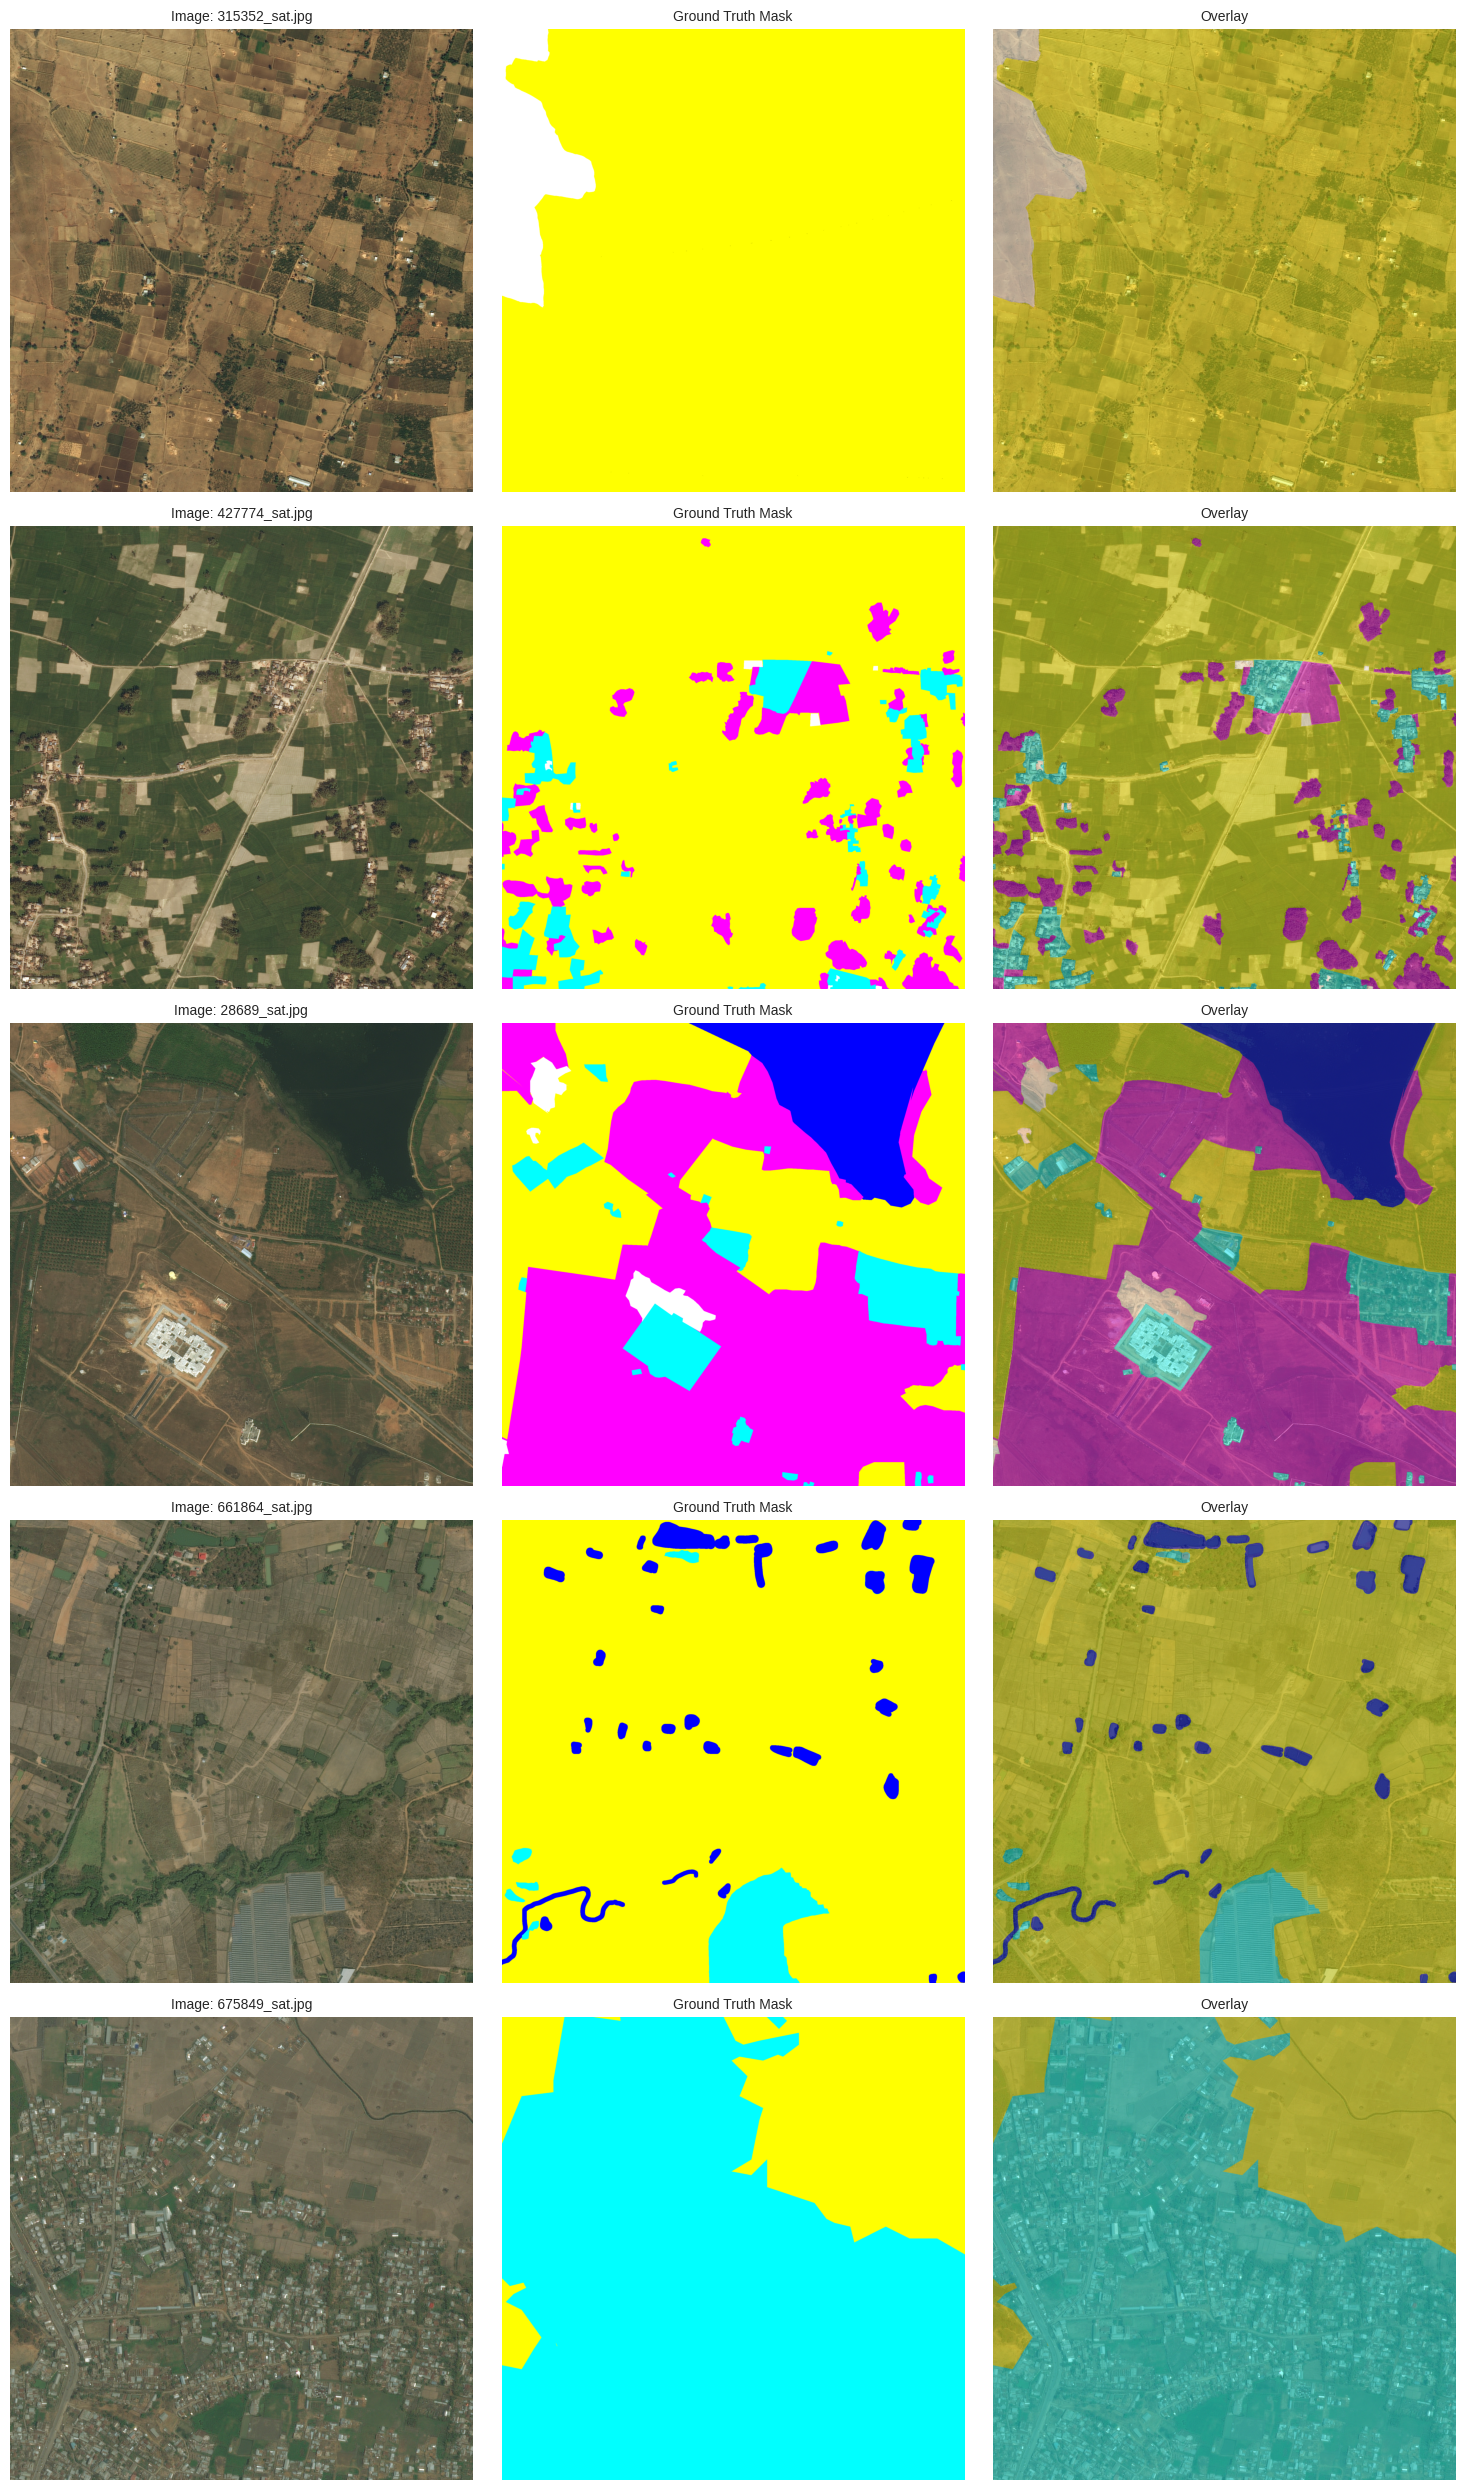


 Graphique de distribution des classes...


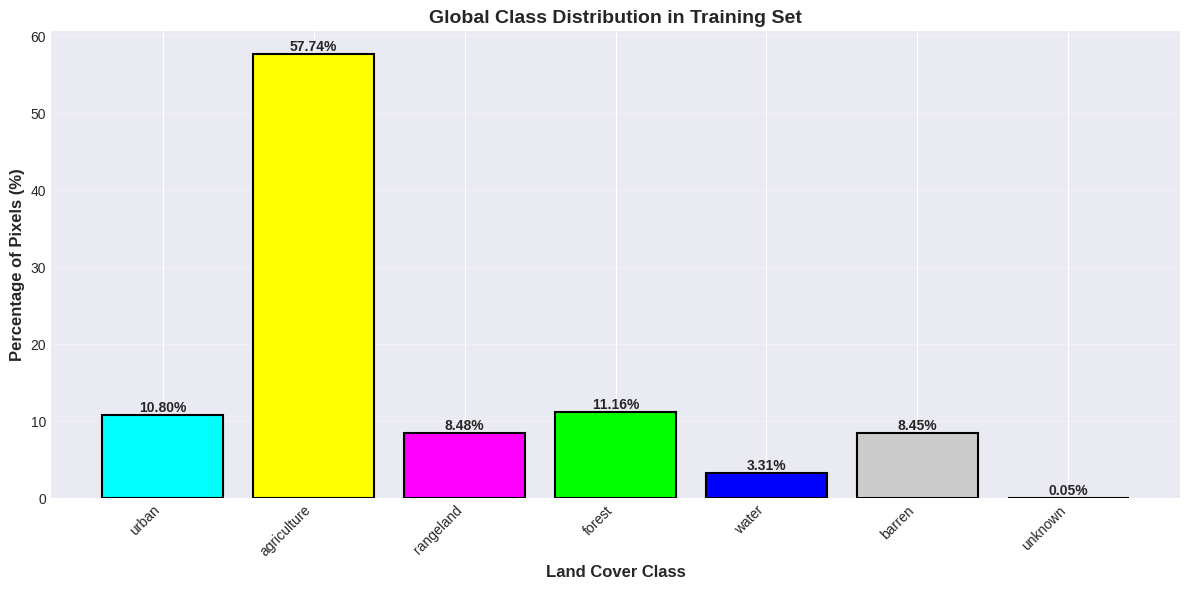


 Visualisation de la complexité des scènes...


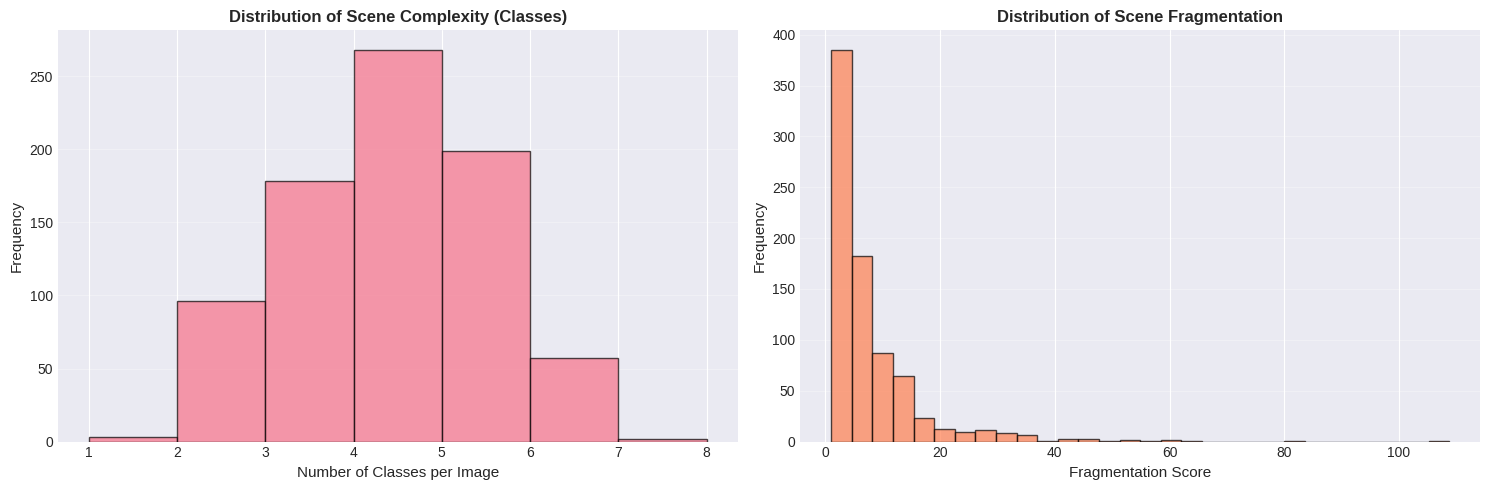


 Distribution des valeurs RGB...


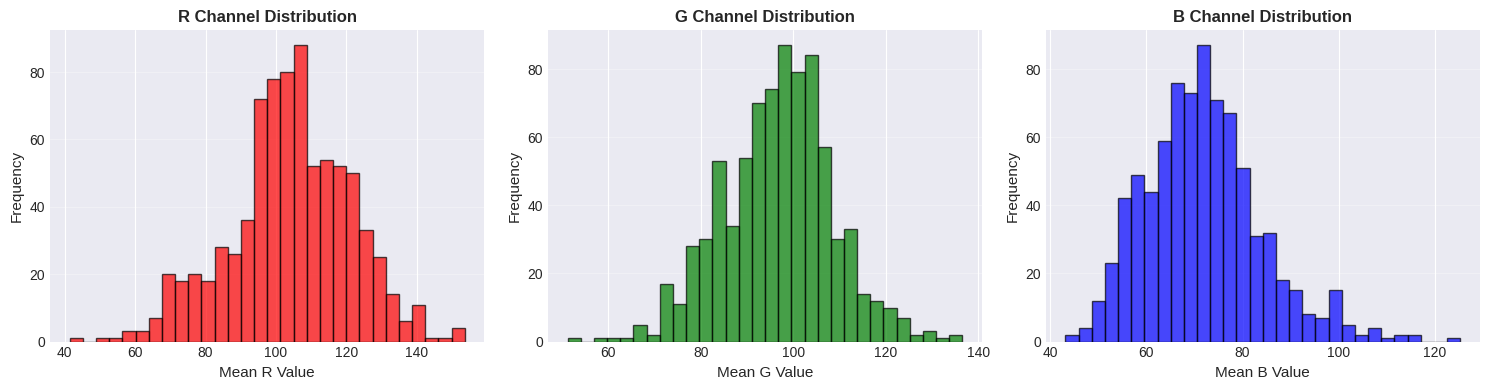

In [ ]:
# ========================================================================================================
# 8. VISUALISATIONS AVANCÉES
# ========================================================================================================
print("\n" + "="*80)
print("8. VISUALISATIONS AVANCÉES")
print("="*80)

# 8.1 Visualisation d'échantillons
def visualize_samples(image_paths, mask_paths, class_colors, n_samples=6, save_path=None):
    """Visualise des échantillons d'images avec leurs masques"""
    n_samples = min(n_samples, len(image_paths))
    indices = np.random.choice(len(image_paths), n_samples, replace=False)

    fig, axes = plt.subplots(n_samples, 3, figsize=(15, 5*n_samples))
    if n_samples == 1:
        axes = axes.reshape(1, -1)

    for i, idx in enumerate(indices):
        img = cv2.imread(str(image_paths[idx]))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        mask_rgb = cv2.imread(str(mask_paths[idx]))
        mask_rgb = cv2.cvtColor(mask_rgb, cv2.COLOR_BGR2RGB)

        overlay = cv2.addWeighted(img, 0.6, mask_rgb, 0.4, 0)

        axes[i, 0].imshow(img)
        axes[i, 0].set_title(f'Image: {image_paths[idx].name}', fontsize=10)
        axes[i, 0].axis('off')

        axes[i, 1].imshow(mask_rgb)
        axes[i, 1].set_title('Ground Truth Mask', fontsize=10)
        axes[i, 1].axis('off')

        axes[i, 2].imshow(overlay)
        axes[i, 2].set_title('Overlay', fontsize=10)
        axes[i, 2].axis('off')

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()

print("\n Visualisation d'échantillons...")
visualize_samples(
    train_images, train_masks, config.CLASS_COLORS,
    n_samples=5,
    save_path=config.FIGURES_DIR / 'sample_visualizations.png'
)

# 8.2 Distribution des classes
print("\n Graphique de distribution des classes...")
fig, ax = plt.subplots(1, 1, figsize=(12, 6))

classes = [config.CLASS_NAMES[i] for i in range(7)]
percentages = [global_class_dist[i] for i in range(7)]
colors_hex = ['#00FFFF', '#FFFF00', '#FF00FF', '#00FF00', '#0000FF', '#CCCCCC', '#000000']

bars = ax.bar(classes, percentages, color=colors_hex, edgecolor='black', linewidth=1.5)
ax.set_ylabel('Percentage of Pixels (%)', fontsize=12, fontweight='bold')
ax.set_xlabel('Land Cover Class', fontsize=12, fontweight='bold')
ax.set_title('Global Class Distribution in Training Set', fontsize=14, fontweight='bold')
ax.grid(axis='y', alpha=0.3)

for bar, pct in zip(bars, percentages):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{pct:.2f}%', ha='center', va='bottom', fontweight='bold')

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / 'class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

# 8.3 Distribution de la complexité des scènes
print("\n Visualisation de la complexité des scènes...")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

num_classes_list = [c['num_classes'] for c in complexity_stats]
fragmentation_list = [c['fragmentation'] for c in complexity_stats]

axes[0].hist(num_classes_list, bins=range(1, 9), edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Number of Classes per Image', fontsize=11)
axes[0].set_ylabel('Frequency', fontsize=11)
axes[0].set_title('Distribution of Scene Complexity (Classes)', fontsize=12, fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)

axes[1].hist(fragmentation_list, bins=30, edgecolor='black', alpha=0.7, color='coral')
axes[1].set_xlabel('Fragmentation Score', fontsize=11)
axes[1].set_ylabel('Frequency', fontsize=11)
axes[1].set_title('Distribution of Scene Fragmentation', fontsize=12, fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(config.FIGURES_DIR / 'scene_complexity.png', dpi=150, bbox_inches='tight')
plt.show()

# 8.4 Statistiques RGB par canal
print("\n Distribution des valeurs RGB...")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for idx, (channel, color) in enumerate([('R', 'red'), ('G', 'green'), ('B', 'blue')]):
    axes[idx].hist(train_stats[f'mean_{channel}'], bins=30,
                   edgecolor='black', alpha=0.7, color=color)
    axes[idx].set_xlabel(f'Mean {channel} Value', fontsize=11)
    axes[idx].set_ylabel('Frequency', fontsize=11)
    axes[idx].set_title(f'{channel} Channel Distribution', fontsize=12, fontweight='bold')
    axes[idx].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(config.FIGURES_DIR / 'rgb_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

## Interprétation des Visualisations

---

### Échantillons d'images avec masques

| Colonne | Description |
|---------|-------------|
| **Gauche** | Image satellite originale |
| **Centre** | Masque de vérité terrain (Ground Truth) |
| **Droite** | Superposition image + masque |

**Observations** :
- Le **jaune (agriculture)** domine largement les masques — confirme les 57.74%
- Les images montrent des paysages variés :  champs, forêts, zones urbaines (cyan), eau (bleu)
- L'overlay permet de vérifier que les masques correspondent bien aux structures visibles

---

### Distribution globale des classes

**Déséquilibre évident** :
- **Agriculture (jaune)** : 57.74% — écrase toutes les autres classes
- **Forest + Urban** : ~11% chacune — classes secondaires
- **Water** : seulement 3.31% — classe rare, difficile à apprendre
- **Unknown** : 0.05% — négligeable, à supprimer

**Impact** : Nécessite des **class weights** pour équilibrer l'apprentissage

---

### Complexité des scènes

**Graphique gauche (nombre de classes)** :
- Pic à **4-5 classes** par image — complexité modérée
- Très peu d'images avec 1-2 classes (simples) ou 7 classes (très complexes)

**Graphique droite (fragmentation)** :
- Majorité des images avec fragmentation **faible (<10)**
- Quelques images très fragmentées (>60) — cas difficiles
- Distribution asymétrique à droite

---

### Distribution RGB

- **Rouge** : centré ~100, distribution large → diversité des sols
- **Vert** :  centré ~95, plus compact → végétation consistante
- **Bleu** : centré ~70, le plus faible → peu d'eau

**Conclusion** : Images terrestres dominées par des tons chauds (végétation, agriculture), cohérent avec le contenu du dataset.

## Cellule 9 :    Calcul des Class Weights

Cette cellule calcule des **poids pour chaque classe** afin de compenser le déséquilibre du dataset lors de l'entraînement.

---

### Deux méthodes de calcul :

#### 1. Méthode "Inverse Frequency" (fréquence inverse)

```python
poids = total_pixels / (nombre_classes × pixels_de_cette_classe)
```

**Principe** : Plus une classe est rare, plus son poids est élevé.

#### 2. Méthode "Effective Number"

```python
effective_num = 1 - β^(fréquence)    # avec β = 0.999
poids = (1 - β) / effective_num
```

**Principe** :  Méthode plus sophistiquée qui gère mieux les cas de déséquilibre extrême (article "Class-Balanced Loss", 2019).

---

### Résultats et Interprétation :

| Classe | Fréquence | Poids (Inverse) | Interprétation |
|--------|-----------|-----------------|----------------|
| **water** | 3.31% | **1.0000** | Classe la plus rare → poids maximum |
| **rangeland** | 8.48% | 0.3904 | Classe rare → poids élevé |
| **barren** | 8.45% | 0.3920 | Classe rare → poids élevé |
| **urban** | 10.80% | 0.3066 | Poids moyen |
| **forest** | 11.16% | 0.2968 | Poids moyen |
| **agriculture** | 57.74% | **0.0574** | Classe dominante → poids très faible |

---

### Comment ces poids fonctionnent :

```
Sans poids :
  Erreur sur agriculture = Erreur sur water = 1

Avec poids :
  Erreur sur agriculture = 1 × 0.0574 = 0.0574  (peu pénalisée)
  Erreur sur water       = 1 × 1.0000 = 1.0000  (très pénalisée)
```

**Effet** : Le modèle sera **17× plus pénalisé** s'il se trompe sur un pixel "water" que sur un pixel "agriculture".

---

### Pourquoi :

| Problème | Solution apportée |
|----------|-------------------|
| Agriculture = 57% | Poids faible (0.057) → réduit son influence |
| Water = 3% | Poids maximum (1.0) → force le modèle à l'apprendre |
| Biais vers classes fréquentes | Équilibrage → toutes les classes comptent également |

In [ ]:
# ========================================================================================================
# 9. CALCUL DES CLASS WEIGHTS
# ========================================================================================================
print("\n" + "="*80)
print("9. CALCUL DES CLASS WEIGHTS")
print("="*80)

def calculate_class_weights(class_distribution: Dict, method: str = 'inverse',
                           exclude_unknown: bool = True) -> Dict:
    """Calcule les poids de classes pour gérer le déséquilibre"""

    if exclude_unknown:
        # Exclure la classe "unknown" (6)
        class_distribution = {k: v for k, v in class_distribution.items() if k != 6}

    if method == 'inverse':
        total = sum(class_distribution.values())
        weights = {class_id: total / (len(class_distribution) * freq)
                   for class_id, freq in class_distribution.items()}

    elif method == 'effective':
        beta = 0.999
        weights = {}
        for class_id, freq in class_distribution.items():
            effective_num = 1.0 - np.power(beta, freq)
            weights[class_id] = (1.0 - beta) / effective_num

    # Normaliser
    max_weight = max(weights.values())
    weights = {k: v/max_weight for k, v in weights.items()}

    return weights

# Calculer les poids avec et sans la classe unknown
class_weights_inverse = calculate_class_weights(global_class_dist, method='inverse',
                                                exclude_unknown=True)
class_weights_effective = calculate_class_weights(global_class_dist, method='effective',
                                                  exclude_unknown=True)

print("\n Class Weights (Inverse Frequency, excluding 'unknown'):")
for class_id, weight in sorted(class_weights_inverse.items()):
    print(f"  {config.CLASS_NAMES[class_id]:15s}: {weight:.4f}")

print("\n Class Weights (Effective Number, excluding 'unknown'):")
for class_id, weight in sorted(class_weights_effective.items()):
    print(f"  {config.CLASS_NAMES[class_id]:15s}: {weight:.4f}")




9. CALCUL DES CLASS WEIGHTS

 Class Weights (Inverse Frequency, excluding 'unknown'):
  urban          : 0.3066
  agriculture    : 0.0574
  rangeland      : 0.3904
  forest         : 0.2968
  water          : 1.0000
  barren         : 0.3920

 Class Weights (Effective Number, excluding 'unknown'):
  urban          : 0.3078
  agriculture    : 0.0589
  rangeland      : 0.3915
  forest         : 0.2979
  water          : 1.0000
  barren         : 0.3930


## Interprétation des Résultats :  Class Weights

---

### Tableau comparatif des deux méthodes

| Classe | Fréquence | Inverse Frequency | Effective Number | Différence |
|--------|-----------|-------------------|------------------|------------|
| **water** | 3.31% | **1.0000** | **1.0000** | 0 |
| rangeland | 8.48% | 0.3904 | 0.3915 | +0.0011 |
| barren | 8.45% | 0.3920 | 0.3930 | +0.0010 |
| urban | 10.80% | 0.3066 | 0.3078 | +0.0012 |
| forest | 11.16% | 0.2968 | 0.2979 | +0.0011 |
| **agriculture** | 57.74% | **0.0574** | **0.0589** | +0.0015 |

---

### Observations clés

#### 1. Water reçoit le poids maximum (1.0)
```
Water = 3.31% → Poids = 1.0000
```
- Classe **la plus rare** du dataset
- Le modèle sera **fortement pénalisé** s'il manque des pixels d'eau
- Compense sa sous-représentation extrême

#### 2. Agriculture reçoit le poids minimum (~0.06)
```
Agriculture = 57.74% → Poids = 0.0574
```
- Classe **dominante** (plus de la moitié des pixels)
- Poids **17× plus faible** que water (1.0 / 0.0574 ≈ 17)
- Évite que le modèle soit biaisé vers agriculture

#### 3. Classes intermédiaires (~0.30-0.39)
```
Rangeland, Barren, Urban, Forest → Poids entre 0.29 et 0.39
```
- Fréquences similaires (8-11%)
- Poids similaires → traitement équilibré

#### 4. Les deux méthodes donnent des résultats quasi-identiques
```
Différence maximale = 0.0015 (négligeable)
```
- **Recommandation** : utiliser "Inverse Frequency" car plus simple à comprendre et implémenter

---

### Impact sur l'entraînement

| Sans class weights | Avec class weights |
|--------------------|-------------------|
| Erreur water = Erreur agriculture | Erreur water = 17× Erreur agriculture |
| Modèle prédit "agriculture" partout | Modèle apprend toutes les classes |
| Accuracy élevée mais mIoU faible | Accuracy plus basse mais mIoU meilleur |

## Cellule 10 :   Traitement de la Classe "Unknown"


Cette cellule **démontre et valide** la suppression de la classe "unknown" (classe 6) en la remplaçant par la classe connue la plus proche spatialement.


---

### Comment fonctionne le remplacement :

```
Avant:   [agriculture] [agriculture] [UNKNOWN] [forest] [forest]
                                       ↓
        Calcul de la distance vers le pixel connu le plus proche
                                       ↓
Après:  [agriculture] [agriculture] [agriculture] [forest] [forest]
```

La fonction utilise la **transformée de distance euclidienne** pour trouver, pour chaque pixel unknown, le pixel connu le plus proche géographiquement.

---

### Pourquoi supprimer "unknown" :

| Raison | Explication |
|--------|-------------|
| **Négligeable** | Seulement 0.05% des pixels |
| **Pas de sens sémantique** | Représente des zones ambiguës/non labellisées |
| **Simplifie le modèle** | Passer de 7 à **6 classes** |
| **Évite la confusion** | Le modèle n'essaiera pas d'apprendre une classe sans signification |


10. TRAITEMENT DE LA CLASSE 'UNKNOWN'

 Remplacement des pixels 'unknown' par la classe la plus proche...
  Exemple sur l'image 829962_mask.png:
    Pixels 'unknown' avant: 0 (0.0000%)
    Pixels 'unknown' après: 0 (0.0000%)


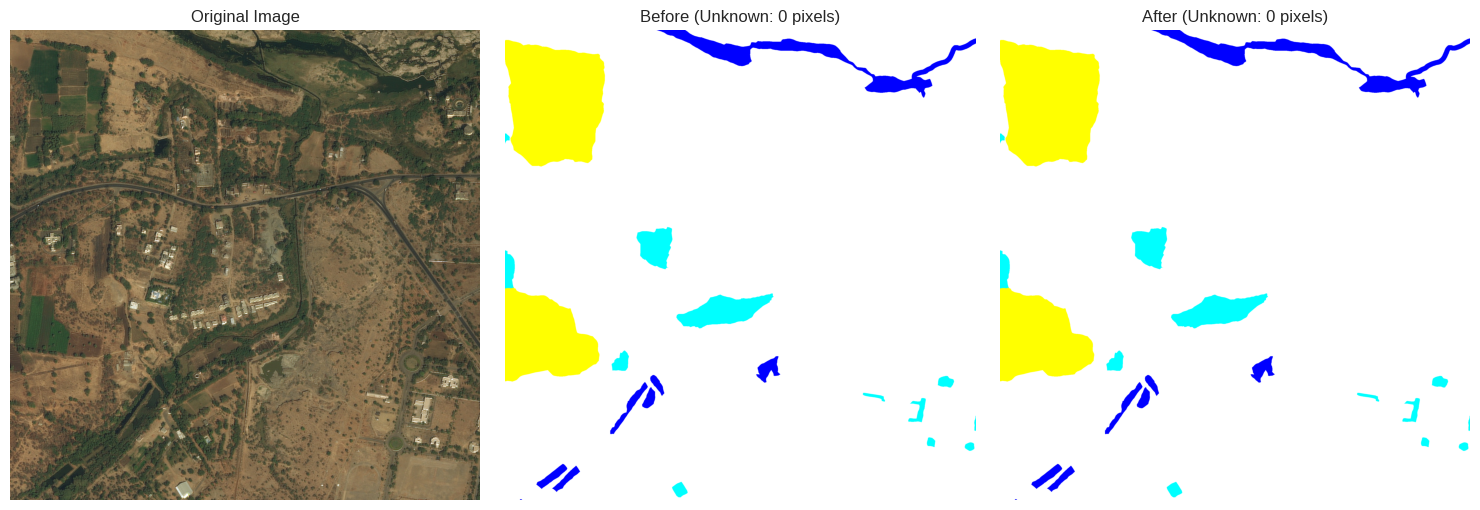


  ✓ La classe 'unknown' sera supprimée lors du prétraitement
  ✓ Nous passerons de 7 classes à 6 classes


In [ ]:
# ========================================================================================================
# 10. TRAITEMENT DE LA CLASSE "UNKNOWN"
# ========================================================================================================
print("\n" + "="*80)
print("10. TRAITEMENT DE LA CLASSE 'UNKNOWN'")
print("="*80)

if config.REMOVE_UNKNOWN_CLASS:
    print("\n Remplacement des pixels 'unknown' par la classe la plus proche...")

    # Tester sur quelques échantillons
    sample_idx = random.randint(0, len(train_masks)-1)
    mask_rgb = cv2.imread(str(train_masks[sample_idx]))
    mask_rgb = cv2.cvtColor(mask_rgb, cv2.COLOR_BGR2RGB)
    mask_class = rgb_to_class_mask(mask_rgb, config.CLASS_COLORS)

    unknown_pixels_before = np.sum(mask_class == 6)
    mask_class_cleaned = replace_unknown_class(mask_class, unknown_class=6)
    unknown_pixels_after = np.sum(mask_class_cleaned == 6)

    print(f"  Exemple sur l'image {train_masks[sample_idx].name}:")
    print(f"    Pixels 'unknown' avant: {unknown_pixels_before} ({unknown_pixels_before/mask_class.size*100:.4f}%)")
    print(f"    Pixels 'unknown' après: {unknown_pixels_after} ({unknown_pixels_after/mask_class.size*100:.4f}%)")

    # Visualiser la différence
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    img = cv2.imread(str(train_images[sample_idx]))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    axes[0].imshow(img)
    axes[0].set_title('Original Image', fontsize=12)
    axes[0].axis('off')

    axes[1].imshow(class_mask_to_rgb(mask_class, config.CLASS_COLORS))
    axes[1].set_title(f'Before (Unknown: {unknown_pixels_before} pixels)', fontsize=12)
    axes[1].axis('off')

    axes[2].imshow(class_mask_to_rgb(mask_class_cleaned, config.CLASS_COLORS))
    axes[2].set_title(f'After (Unknown: {unknown_pixels_after} pixels)', fontsize=12)
    axes[2].axis('off')

    plt.tight_layout()
    plt.savefig(config.FIGURES_DIR / 'unknown_class_removal.png', dpi=150, bbox_inches='tight')
    plt.show()

    print("\n  ✓ La classe 'unknown' sera supprimée lors du prétraitement")
    print("  ✓ Nous passerons de 7 classes à 6 classes")

### Pourquoi cette méthode :

| Avantage | Explication |
|----------|-------------|
| **Spatiale** | Utilise la proximité géographique (logique pour images satellites) |
| **Cohérente** | Un pixel unknown près d'une forêt devient forêt |
| **Efficace** | `distance_transform_edt` est optimisé (algorithme rapide) |
| **Pas de perte** | Aucun pixel n'est supprimé, tous sont réaffectés |

## Cellule 11 :    Split Train/Validation Stratifié

Diviser les 803 images en **train (642)** et **validation (161)** de manière stratifiée.

---

### Stratification :    Comment ça marche ?  

1. **Identifier la classe dominante** de chaque image (ex: 60% agriculture → "agriculture")
2. **Garantir les mêmes proportions** de chaque type d'image dans train ET validation

---

### Pourquoi stratifier :  

| Problème (split aléatoire) | Solution (stratifié) |
|----------------------------|----------------------|
| Toutes les images "water" pourraient aller dans train | Water réparti 80/20 dans train/val |
| Validation non représentative | Proportions identiques |
| Métriques de validation biaisées | Évaluation fiable |

---

### Résultat :

```
Train:        642 images (80%)
Validation: 161 images (20%)
Test:       172 images (séparé)
```

Les indices sont sauvegardés pour **reproductibilité**.

In [ ]:
# ========================================================================================================
# 11. CRÉATION DU SPLIT TRAIN/VALIDATION STRATIFIÉ
# ========================================================================================================
print("\n" + "="*80)
print("11. CRÉATION DU SPLIT TRAIN/VALIDATION STRATIFIÉ")
print("="*80)

def create_stratified_split(image_paths: List[Path], mask_paths: List[Path],
                           class_colors: Dict, val_split: float = 0.2,
                           seed: int = 42) -> Tuple:
    """Crée un split stratifié basé sur la classe dominante de chaque image"""
    np.random.seed(seed)

    # Déterminer la classe dominante pour chaque image
    dominant_classes = []
    for mask_path in tqdm(mask_paths, desc="Computing dominant classes"):
        mask_rgb = cv2.imread(str(mask_path))
        mask_rgb = cv2.cvtColor(mask_rgb, cv2.COLOR_BGR2RGB)
        mask_class = rgb_to_class_mask(mask_rgb, class_colors)

        # Trouver la classe dominante (exclure unknown si présent)
        unique, counts = np.unique(mask_class[mask_class != 6], return_counts=True)
        if len(unique) > 0:
            dominant = unique[np.argmax(counts)]
        else:
            dominant = 0  # Fallback
        dominant_classes.append(dominant)

    dominant_classes = np.array(dominant_classes)

    # Stratified split
    from sklearn.model_selection import train_test_split
    indices = np.arange(len(image_paths))

    train_idx, val_idx = train_test_split(
        indices, test_size=val_split, random_state=seed,
        stratify=dominant_classes
    )

    train_imgs = [image_paths[i] for i in train_idx]
    train_msks = [mask_paths[i] for i in train_idx]
    val_imgs = [image_paths[i] for i in val_idx]
    val_msks = [mask_paths[i] for i in val_idx]

    return train_imgs, train_msks, val_imgs, val_msks, train_idx, val_idx

train_imgs, train_msks, val_imgs, val_msks, train_idx, val_idx = create_stratified_split(
    train_images, train_masks, config.CLASS_COLORS,
    val_split=config.VAL_SPLIT, seed=config.SEED
)

print(f"\n Split stratifié créé:")
print(f"  • Training set: {len(train_imgs)} images")
print(f"  • Validation set: {len(val_imgs)} images")
print(f"  • Test set: {len(test_images)} images")
print(f"  • Ratio: {(1-config.VAL_SPLIT)*100:.0f}% train / {config.VAL_SPLIT*100:.0f}% val")



11. CRÉATION DU SPLIT TRAIN/VALIDATION STRATIFIÉ


Computing dominant classes:   0%|          | 0/803 [00:00<?, ?it/s]


 Split stratifié créé:
  • Training set: 642 images
  • Validation set: 161 images
  • Test set: 172 images
  • Ratio: 80% train / 20% val


## Cellule 12 :     Prétraitement et Sauvegarde des Données


Transformer les images brutes en données prêtes pour U-Net et les sauvegarder en fichiers `.npy`.

---

### Opérations de prétraitement :

| Étape | Image | Masque |
|-------|-------|--------|
| **Lecture** | `cv2.imread()` | `cv2.imread()` |
| **Conversion couleur** | BGR → RGB | BGR → RGB |
| **Redimensionnement** | 2448×2448 → **256×256** | 2448×2448 → **256×256** |
| **Interpolation** | `INTER_LINEAR` (lisse) | `INTER_NEAREST` (préserve classes) |
| **Normalisation** | [0-255] → **[0-1]** | — |
| **Conversion** | — | RGB → indices (0-5) |
| **Suppression unknown** | — | Classe 6 → classe voisine |

---

### Pourquoi ces choix :

| Choix | Raison |
|-------|--------|
| **256×256** | Taille gérable pour GPU (2448×2448 trop grand) |
| **INTER_LINEAR pour images** | Interpolation douce, préserve les détails |
| **INTER_NEAREST pour masques** | Préserve les valeurs exactes des classes (pas d'interpolation) |
| **Normalisation [0-1]** | Standard pour réseaux de neurones |
| **Format .npy** | Chargement ultra-rapide pendant l'entraînement |

---

### Fichiers générés :

```
✓ train_images.npy  →  (642, 256, 256, 3)   float32
✓ train_masks.npy   →  (642, 256, 256)      uint8
✓ val_images.npy    →  (161, 256, 256, 3)   float32
✓ val_masks.npy     →  (161, 256, 256)      uint8
✓ test_images.npy   →  (172, 256, 256, 3)   float32
```

---

### Note importante :

Le **test set** n'a pas de masques (`None`) — ils serviront uniquement pour l'évaluation finale après entraînement.  

In [ ]:
# ========================================================================================================
# 12. PRÉTRAITEMENT ET SAUVEGARDE
# ========================================================================================================
print("\n" + "="*80)
print("12. PRÉTRAITEMENT ET SAUVEGARDE DES DONNÉES")
print("="*80)

def preprocess_and_save_data(image_paths: List[Path], mask_paths: Optional[List[Path]],
                            output_file_img: Path, output_file_mask: Optional[Path],
                            target_size: Tuple[int, int], class_colors: Dict,
                            remove_unknown: bool = True):
    """Prétraite et sauvegarde les données"""
    n_samples = len(image_paths)
    num_classes = 6 if remove_unknown else 7

    images = np.zeros((n_samples, target_size[0], target_size[1], 3), dtype=np.float32)

    if mask_paths is not None:
        masks = np.zeros((n_samples, target_size[0], target_size[1]), dtype=np.uint8)

    for i, img_path in enumerate(tqdm(image_paths, desc=f"Processing {output_file_img.stem}")):
        # Image
        img = cv2.imread(str(img_path))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, target_size, interpolation=cv2.INTER_LINEAR)
        img = img.astype(np.float32) / 255.0
        images[i] = img

        # Mask
        if mask_paths is not None:
            mask_rgb = cv2.imread(str(mask_paths[i]))
            mask_rgb = cv2.cvtColor(mask_rgb, cv2.COLOR_BGR2RGB)
            mask_rgb = cv2.resize(mask_rgb, target_size, interpolation=cv2.INTER_NEAREST)
            mask_class = rgb_to_class_mask(mask_rgb, class_colors)

            if remove_unknown:
                mask_class = replace_unknown_class(mask_class, unknown_class=6)

            masks[i] = mask_class

    np.save(output_file_img, images)
    print(f"  ✓ Images saved: {output_file_img} (shape: {images.shape})")

    if mask_paths is not None:
        np.save(output_file_mask, masks)
        print(f"  ✓ Masks saved: {output_file_mask} (shape: {masks.shape})")

print("\n Prétraitement et sauvegarde...")

# Training set
preprocess_and_save_data(
    train_imgs, train_msks,
    config.OUTPUT_DIR / 'train_images.npy',
    config.OUTPUT_DIR / 'train_masks.npy',
    config.TARGET_SIZE, config.CLASS_COLORS,
    remove_unknown=config.REMOVE_UNKNOWN_CLASS
)

# Validation set
preprocess_and_save_data(
    val_imgs, val_msks,
    config.OUTPUT_DIR / 'val_images.npy',
    config.OUTPUT_DIR / 'val_masks.npy',
    config.TARGET_SIZE, config.CLASS_COLORS,
    remove_unknown=config.REMOVE_UNKNOWN_CLASS
)

# Test set
preprocess_and_save_data(
    test_images, None,
    config.OUTPUT_DIR / 'test_images.npy', None,
    config.TARGET_SIZE, config.CLASS_COLORS,
    remove_unknown=False
)



12. PRÉTRAITEMENT ET SAUVEGARDE DES DONNÉES

 Prétraitement et sauvegarde...


Processing train_images:   0%|          | 0/642 [00:00<?, ?it/s]

  ✓ Images saved: /kaggle/working/preprocessed_data/train_images.npy (shape: (642, 256, 256, 3))
  ✓ Masks saved: /kaggle/working/preprocessed_data/train_masks.npy (shape: (642, 256, 256))


Processing val_images:   0%|          | 0/161 [00:00<?, ?it/s]

  ✓ Images saved: /kaggle/working/preprocessed_data/val_images.npy (shape: (161, 256, 256, 3))
  ✓ Masks saved: /kaggle/working/preprocessed_data/val_masks.npy (shape: (161, 256, 256))


Processing test_images:   0%|          | 0/172 [00:00<?, ?it/s]

  ✓ Images saved: /kaggle/working/preprocessed_data/test_images.npy (shape: (172, 256, 256, 3))



### Dans la fonction `preprocess_and_save_data()` :

```python
# Pour les IMAGES → INTER_LINEAR
img = cv2.resize(img, target_size, interpolation=cv2.INTER_LINEAR)

# Pour les MASQUES → INTER_NEAREST
mask_rgb = cv2.resize(mask_rgb, target_size, interpolation=cv2.INTER_NEAREST)
```

---


```
Redimensionnement:   2448×2448  →  256×256

┌─────────────────────────────────────────────────────────────┐
│                    IMAGES (*. jpg)                          │
│                                                             │
│   2448×2448  ──INTER_LINEAR──►  256×256                     │
│   (grande)                       (petite, lisse)            │
└─────────────────────────────────────────────────────────────┘

┌─────────────────────────────────────────────────────────────┐
│                    MASQUES (*.png)                          │
│                                                             │
│   2448×2448  ──INTER_NEAREST──►  256×256                    │
│   (grande)                        (petite, classes exactes) │
└─────────────────────────────────────────────────────────────┘
```

---

### Résumé :

| Quand ?  | Quoi ? | Méthode |
|---------|--------|---------|
| Prétraitement des **642 images train** | Redimensionner | INTER_LINEAR |
| Prétraitement des **642 masques train** | Redimensionner | INTER_NEAREST |
| Prétraitement des **161 images val** | Redimensionner | INTER_LINEAR |
| Prétraitement des **161 masques val** | Redimensionner | INTER_NEAREST |
| Prétraitement des **172 images test** | Redimensionner | INTER_LINEAR |

## Cellule 13 :      Génération des Métadonnées  

Sauvegarder **toutes les informations** du prétraitement dans des fichiers JSON pour les réutiliser dans les notebooks suivants.

---

### Contenu du fichier `metadata.json` :

| Section | Informations sauvegardées |
|---------|---------------------------|
| **data_splits** | Tailles train/val/test, indices exacts du split |
| **image_properties** | Taille originale (2448), taille cible (256), format |
| **normalization** | Stats ImageNet + stats calculées du dataset |
| **classes** | 6 classes, noms, unknown supprimé |
| **class_distribution** | Pourcentages de chaque classe |
| **class_weights** | Poids pour équilibrer l'entraînement |
| **scene_complexity** | Fragmentation moyenne, classes par image |
| **files_generated** | Chemins des fichiers . npy créés |

---

### Fichiers générés :

```
✓ metadata.json       → Toutes les infos du prétraitement
✓ class_weights.json  → Poids des classes (inverse + effective)
```

In [ ]:
# ========================================================================================================
# 13. GÉNÉRATION DES MÉTADONNÉES
# ========================================================================================================
print("\n" + "="*80)
print("13. GÉNÉRATION DES MÉTADONNÉES")
print("="*80)

# Recalculer la distribution sans unknown
if config.REMOVE_UNKNOWN_CLASS:
    global_class_dist_clean = {k: v for k, v in global_class_dist.items() if k != 6}
    total = sum(global_class_dist_clean.values())
    global_class_dist_clean = {k: (v/total)*100 for k, v in global_class_dist_clean.items()}
    final_num_classes = 6
    final_class_names = config.CLASS_NAMES[:-1]
else:
    global_class_dist_clean = global_class_dist
    final_num_classes = 7
    final_class_names = config.CLASS_NAMES

metadata = {
    "project_name": "DeepGlobe Land Cover Segmentation",
    "dataset": "DeepGlobe Land Cover Classification Dataset",
    "preprocessing_date": datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
    "random_seed": config.SEED,

    "data_splits": {
        "train_size": len(train_imgs),
        "val_size": len(val_imgs),
        "test_size": len(test_images),
        "val_split_ratio": config.VAL_SPLIT,
        "split_strategy": "stratified (based on dominant class)",
        "train_indices": train_idx.tolist(),
        "val_indices": val_idx.tolist()
    },

    "image_properties": {
        "original_size": [2448, 2448],
        "target_size": list(config.TARGET_SIZE),
        "channels": 3,
        "format": "RGB",
        "dtype": "float32",
        "value_range": "[0, 1]"
    },

    "normalization": {
        "applied_in_preprocessing": False,
        "imagenet_stats": {
            "mean": config.MEAN,
            "std": config.STD
        },
        "dataset_stats": {
            "mean": [dataset_mean_R, dataset_mean_G, dataset_mean_B],
            "std": [dataset_std_R, dataset_std_G, dataset_std_B]
        } if config.COMPUTE_DATASET_STATS else None,
        "note": "Apply normalization in DataLoader during training"
    },

    "classes": {
        "num_classes": final_num_classes,
        "class_names": final_class_names,
        "unknown_class_removed": config.REMOVE_UNKNOWN_CLASS,
        "class_encoding": f"single channel with values 0-{final_num_classes-1}"
    },

    "class_distribution": {
        "original_with_unknown": {config.CLASS_NAMES[k]: f"{v:.2f}%"
                                 for k, v in global_class_dist.items()},
        "final_without_unknown": {config.CLASS_NAMES[k]: f"{v:.2f}%"
                                 for k, v in global_class_dist_clean.items()},
        "imbalance_analysis": {
            "most_frequent": config.CLASS_NAMES[max_class],
            "least_frequent": config.CLASS_NAMES[min_class],
            "ratio": f"{ratio:.2f}x"
        }
    },

    "class_weights": {
        "inverse_frequency": {config.CLASS_NAMES[k]: float(f"{v:.4f}")
                             for k, v in class_weights_inverse.items()},
        "effective_number": {config.CLASS_NAMES[k]: float(f"{v:.4f}")
                            for k, v in class_weights_effective.items()}
    },

    "scene_complexity": {
        "avg_classes_per_image": float(f"{avg_num_classes:.2f}"),
        "avg_segments_per_image": int(avg_segments),
        "avg_fragmentation": float(f"{avg_fragmentation:.2f}")
    },

    "files_generated": {
        "train_images": str(config.OUTPUT_DIR / 'train_images.npy'),
        "train_masks": str(config.OUTPUT_DIR / 'train_masks.npy'),
        "val_images": str(config.OUTPUT_DIR / 'val_images.npy'),
        "val_masks": str(config.OUTPUT_DIR / 'val_masks.npy'),
        "test_images": str(config.OUTPUT_DIR / 'test_images.npy'),
        "metadata": str(config.OUTPUT_DIR / 'metadata.json'),
        "class_weights": str(config.OUTPUT_DIR / 'class_weights.json')
    },

    "notes": [
        "Images resized to 256x256 for computational efficiency",
        "Masks use INTER_NEAREST to preserve class labels",
        "Unknown class (6) replaced with nearest known class",
        "Stratified split ensures balanced class representation",
        "Train/val indices saved for reproducibility",
        "Dataset statistics computed for potential custom normalization",
        "Class weights computed to handle class imbalance"
    ]
}

# Sauvegarder métadonnées
metadata_path = config.OUTPUT_DIR / 'metadata.json'
with open(metadata_path, 'w') as f:
    json.dump(metadata, f, indent=2)
print(f"\n✓ Metadata saved: {metadata_path}")

# Sauvegarder class weights
weights_path = config.OUTPUT_DIR / 'class_weights.json'
with open(weights_path, 'w') as f:
    json.dump({
        "inverse_frequency": class_weights_inverse,
        "effective_number": class_weights_effective
    }, f, indent=2)
print(f"✓ Class weights saved: {weights_path}")


13. GÉNÉRATION DES MÉTADONNÉES

✓ Metadata saved: /kaggle/working/preprocessed_data/metadata.json
✓ Class weights saved: /kaggle/working/preprocessed_data/class_weights.json


## Cellule 14 :     Résumé Final

### Ce qu'on a accompli :

---

### Données préparées :

| Ensemble | Images | Masques | Usage |
|----------|--------|---------|-------|
| **Train** | 642 | 642 | Entraînement du modèle |
| **Validation** | 161 | 161 | Évaluation pendant l'entraînement |
| **Test** | 172 | _ | Évaluation finale |

---

### Transformations appliquées :

```
Images originales          →          Images prêtes pour U-Net
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
2448 × 2448                →          256 × 256
[0-255] entiers            →          [0-1] float32
7 classes                  →          6 classes (sans unknown)
Fichiers JPG/PNG           →          Fichiers . npy
```

---

### Fichiers générés :

| Fichier | Contenu |
|---------|---------|
| `train_images.npy` | (642, 256, 256, 3) - Images train |
| `train_masks.npy` | (642, 256, 256) - Masques train |
| `val_images.npy` | (161, 256, 256, 3) - Images validation |
| `val_masks.npy` | (161, 256, 256) - Masques validation |
| `test_images.npy` | (172, 256, 256, 3) - Images test |
| `metadata.json` | Toutes les infos du prétraitement |
| `class_weights.json` | Poids pour équilibrer les classes |

---

### Class Weights à utiliser :

| Classe | Poids | Signification |
|--------|-------|---------------|
| water | **1.0000** | Classe rare → poids max |
| rangeland | 0.3904 | Poids élevé |
| barren | 0.3920 | Poids élevé |
| urban | 0.3066 | Poids moyen |
| forest | 0.2968 | Poids moyen |
| agriculture | **0.0574** | Classe dominante → poids min |